## Module 3: Computational Drug Discovery Project

Destiny Suarez and Tallen Avellaneda

## Project Goal:
Our goal is to computationally evaluate Cavalitide, a proposed GLP-1 receptor agonist, as a potential competitor to semaglutide, such as Ozempic or Wegovy. We used pharmacological modeling to investigate Cavalitide's receptor binding affinity and compare it with semaglutide. We also simulated its drug absorption and concentration over time to optimize its daily oral dosage. Finally, we combined the pharmacokinetic and pharmacodynamic models to predict GLP-1 receptor activation over time and optimize dosing toward approximately 90% receptor activation.

## Disease Background: 
Obesity is one of the biggest public health problems in the U.S., affecting about 40.3% of adults (Emmerich et al., 2024). When the body stores too much fat, it starts to interfere with how organs and hormones work, and the extra weight puts constant strain on the body. That strain can raise blood pressure and lead to heart problems, and over time the fat buildup can make the body resistant to insulin, which can turn into type 2 diabetes (Emmerich et al., 2024). The usual first step in treatment is changing daily habits, like paying attention to what you eat and getting regular exercise. When that isn't enough, doctors can also prescribe medications like GLP-1s, which help with weight loss by regulating appetite, blood sugar, and weight gain (Moiz et al., 2025).

GLP-1 is a hormone that is naturally released by cells in the intestine after eating. It binds to GLP-1 receptors found in the pancreas and nervous system. In the pancreas, GLP-1 stimulates insulin release when blood sugar is elevated and reduces the release of glucagon, a hormone that raises blood sugar. It also slows gastric emptying, meaning food leaves the stomach more slowly, and acts on areas of the brain involved in appetite and fullness. Together, these effects help regulate blood sugar, reduce hunger and food intake, and support weight loss (Drucker, 2022).

That matters because obesity isn't just a willpower issue; GLP-1 medications work with the body's natural biological pathways. This is where our Cavalitide project comes in. We're trying to find the dosage that gives the best results for patients and ultimately make our medication more effective than competing options so more people can manage their obesity.

## Task 1: Fit a receptor binding model for Cavalitide:

Your colleague in Lead Discovery has identified a small molecule, Cavalitide, and performed experiments testing its binding to the GLP1 receptor (below, and available as cavalitide_data.csv). You now aim to develop a pharmacodynamics model of how GLP1 and Cavalitide can each bind and activate the GLP1 receptor. 
a)	Adapt your previous codes for modeling semaglutide (fit_semaglutide.py, semaglutide_data.csv) to fit the Cavalitide binding data. 
b)	Show a plot of [Cavalitide] vs. Fraction active receptors (Fact) demonstrating a good fit.
c)	Provide the fitted value of Kd for Cavalitide. Interpret the Kd of Cavalitide versus that of semaglutide, commenting on advantages/disadvantages.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score

def Fact(L1, L2, Kd1, Kd2):
    # Fractional receptor activation with two agonists L1 and L2
    return (Kd2*L1+Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)

def find_kd(Kd1, L1, L2_loaded, Fact_loaded):

    # creates lists for comparing the best curve fit that gives the least SSE
    kd2_fit_list = []
    sse_vals = []
    Kd2_candidates = np.logspace(-4, 3, 10) # [nM]

    # adds each curve fit attempt into the the kd2_fit_list and its corresponding SSE
    for testpoint in Kd2_candidates:
        popt, pcov = curve_fit(lambda L2, testpoint: Fact(L1, L2, Kd1, testpoint),
                            L2_loaded, Fact_loaded, p0=[testpoint], bounds=(0, np.inf))
        Kd2_fit = popt[0]
        kd2_fit_list.append(float(popt[0]))
        sse_vals.append(np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_fit))**2))

    # variables to compare SSEs
    min = sse_vals[0]
    i = 0
    index = 0

    # finds the index of the lowest SSE
    for val in sse_vals:
        if val < min:
            min = val
            index = i
        i += 1

    # returns the Kd2 that gives the best fit (lowest SSE)
    best_kd2 = kd2_fit_list[index]
    predicted = Fact(L1, L2_loaded, Kd1, best_kd2)
    r_squared = r2_score(Fact_loaded, predicted)
    print(f"Fitted Kd2 = {best_kd2:.3f} nM (SSE = {sse_vals[index]:.4f}, R^2 = {r_squared:.4f})")
    return best_kd2, r_squared


Kd1 = 0.17 # L1, GLP1
L1 = 0.015 # [nM] GLP1 (fasting)
L2 = np.logspace(-4, 3, 500) # [nM] semaglutide or cavalitide

cav_data = np.loadtxt("cavalitide_data.csv", delimiter=",", skiprows=1)
sema_data = np.loadtxt("semaglutide_data.csv", delimiter=",", skiprows=1)
cav_L2_loaded, cav_Fact_loaded = cav_data[:, 0], cav_data[:, 1]
sema_L2_loaded, sema_Fact_loaded = sema_data[:, 0], sema_data[:, 1]

print("Cavalitide Kd2:")
cav_best_kd2, cav_r_squared = find_kd(Kd1, L1, cav_L2_loaded, cav_Fact_loaded)
print("-------------------------")
print("Semaglutide Kd2:")
sema_best_kd2, sema_r_squared = find_kd(Kd1, L1, sema_L2_loaded, sema_Fact_loaded)
print("-------------------------")

plt.figure()
plt.semilogx(cav_L2_loaded, cav_Fact_loaded, "o", c="blue",
            label="Cavalitide Experimental Data")
plt.semilogx(sema_L2_loaded, sema_Fact_loaded, "o", c="orange",
            label="Semaglutide Experimental Data")
plt.semilogx(L2, Fact(L1, L2, Kd1, cav_best_kd2), "--", c = "blue", lw=2,
            label=f"Cavalitide Model (Kd2 = {cav_best_kd2:.3f} nM)")
plt.semilogx(L2, Fact(L1, L2, Kd1, sema_best_kd2), "--", c = "orange", lw=2,
            label=f"Semaglutide Model (Kd2 = {sema_best_kd2:.3f} nM)")

plt.axhline(0.5, ls=":", c="black", lw=1)
plt.text(0.00005, 0.525, "Fact = 0.5")
plt.text(0.00005, 0.800, f"R^2 = {cav_r_squared}", c = "blue")
plt.text(0.00005, 0.750, f"R^2 = {sema_r_squared}", c = "orange")
plt.ylim(-0.1, 1.1)
plt.xlabel("[Drug] (nM)")
plt.ylabel("Fraction Active (Fact)")
plt.title("Comparing GLP1R Activation between Semaglutide and Cavalitide")
plt.legend(loc="upper left", fontsize = 7)
plt.show()

## Task 2: Simulate the pharmacokinetics of Cavalitide treatment
2a. Comparing Ozempic and Wegovy Pharmacokinetics

We first adapted the semaglutide pharmacokinetic model to simulate both Ozempic, which is administered as a once-weekly subcutaneous injection, and Wegovy, which is taken as a daily oral pill. We replaced the original explicit Euler method with the solve_ivp function from SciPy to solve the pharmacokinetic differential equations. The model tracks drug absorption through a depot compartment and drug elimination from a central blood compartment. We simulated 8 weekly doses of Ozempic and 100 daily doses of Wegovy, then plotted their predicted free blood concentration profiles. The results showed different concentration patterns due to their dosing schedules, bioavailability, and absorption rates. These simulations allowed us to compare how injectable and oral administration affect semaglutide concentrations over time.

2b. Simulating Cavalitide as a Daily Oral Medication

Next, we adapted the pharmacokinetic model to simulate Cavalitide as a daily oral medication. We used the absorption rate specified in the project instructions, ka = 0.006 h⁻¹, with a dosing interval of 24 hours. We simulated 100 repeated doses to observe how Cavalitide accumulated over time. In the code, we used a dosing loop to add each new dose to the absorption compartment and used solve_ivp to calculate how the drug was absorbed and eliminated between doses. The predicted free blood concentration gradually increased and approached a steady-state level. This occurs when the amount of drug entering the bloodstream becomes balanced by the amount being eliminated.

2c. Optimizing the Cavalitide Dose

To achieve the target steady-state free blood concentration of approximately 0.5 nM, we compared two daily Cavalitide doses while keeping the dosing interval at 24 hours. We initially tested a 25 mg daily dose, which produced a free blood concentration of approximately 0.60 nM. Since this was higher than our target, we reduced the daily dose to 21 mg, which brought the predicted concentration closer to 0.50 nM.

In the code, we simulated both doses and plotted their concentration profiles on the same graph. We added a horizontal reference line at 0.5 nM to make it easier to compare each dose with the target. The results showed that the 21 mg dose was a closer match to the desired steady-state concentration than the 25 mg dose. We selected 21 mg daily as our optimized dose for Task 2 and used it as the starting point for the combined pharmacokinetic-pharmacodynamic model in Task 3.

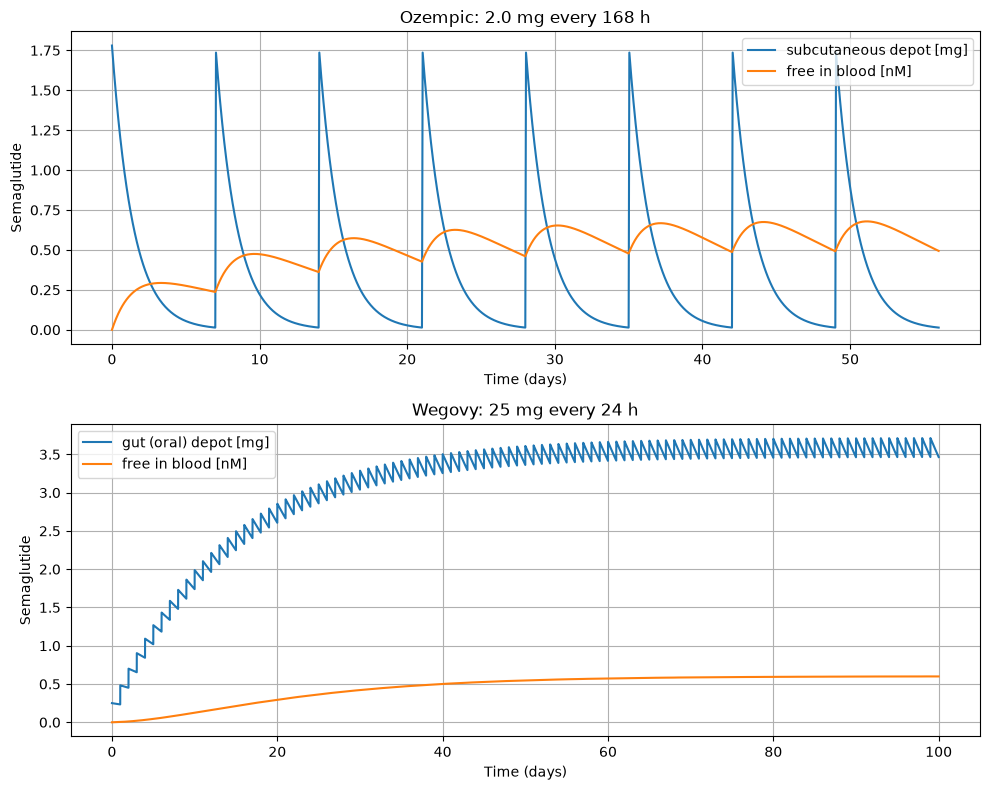

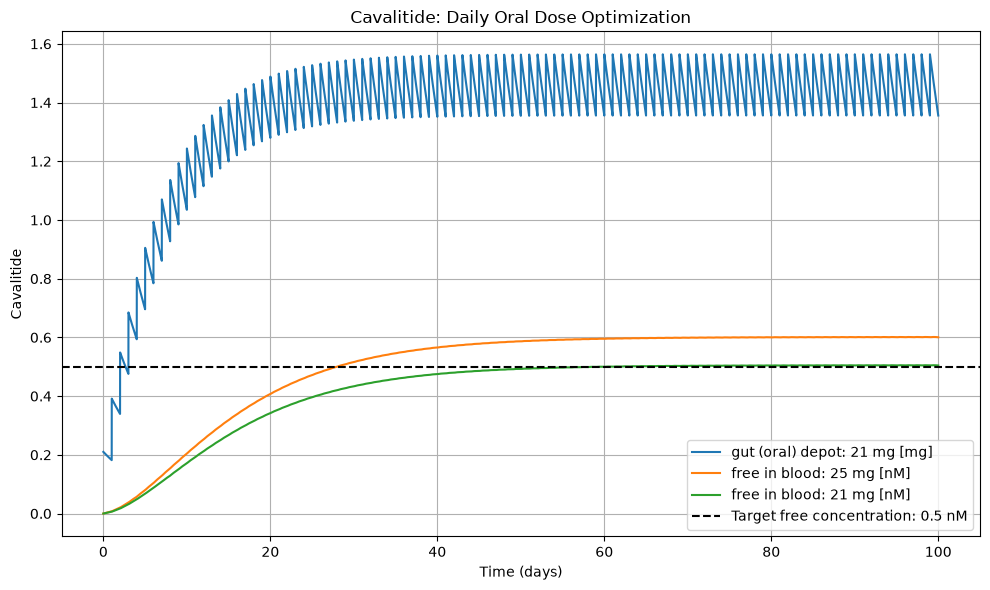

25 mg daily: 0.600 nM
21 mg daily: 0.504 nM


In [7]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Pharmacokinetic parameters
ke = 0.0039          # Elimination rate (1/h)
V = 10.8             # Volume of distribution (L)
MW = 4113.6          # Molecular weight (g/mol)
Ffree = 0.01         # Free drug fraction


# Convert concentration from mg/L to free nM
def convert_to_nM(C):
    return C * (1e6 / MW) * Ffree


# Pharmacokinetic differential equations
def pk_model(t, y, ka):
    gut, blood = y

    d_gut = -ka * gut
    d_blood = (ka * gut / V) - (ke * blood)

    return [d_gut, d_blood]


# Simulate repeated doses using solve_ivp
def simulate_PK(dose, Favailable, ka, interval, n_doses):

    gut = 0
    blood = 0

    times = []
    gut_values = []
    blood_values = []

    for i in range(n_doses):

        # Add the next dose to the gut/depot compartment
        gut += dose * Favailable

        # Set the time interval for this dose
        t_start = i * interval
        t_end = (i + 1) * interval

        t_eval = np.linspace(t_start, t_end, 150)

        # Solve the differential equations
        sol = solve_ivp(
            pk_model,
            [t_start, t_end],
            [gut, blood],
            args=(ka,),
            t_eval=t_eval
        )

        # Store the results
        if i == 0:
            times.extend(sol.t)
            gut_values.extend(sol.y[0])
            blood_values.extend(sol.y[1])
        else:
            times.extend(sol.t[1:])
            gut_values.extend(sol.y[0][1:])
            blood_values.extend(sol.y[1][1:])

        # Carry remaining drug into the next dosing interval
        gut = sol.y[0][-1]
        blood = sol.y[1][-1]

    return (
        np.array(times),
        np.array(gut_values),
        convert_to_nM(np.array(blood_values))
    )


# ==================================================
# TASK 2A: OZEMPIC AND WEGOVY
# ==================================================

# Ozempic: 2 mg weekly subcutaneous injection
t_O, gut_O, blood_O = simulate_PK(
    dose=2,
    Favailable=0.89,
    ka=0.029,
    interval=168,
    n_doses=8
)

# Wegovy: 25 mg daily oral medication
t_W, gut_W, blood_W = simulate_PK(
    dose=25,
    Favailable=0.01,
    ka=0.0029,
    interval=24,
    n_doses=100
)

# Plot Ozempic and Wegovy separately
fig, axes = plt.subplots(2, 1, figsize=(10, 8))

# Ozempic
axes[0].plot(t_O / 24, gut_O,
             label="subcutaneous depot [mg]")
axes[0].plot(t_O / 24, blood_O,
             label="free in blood [nM]")

axes[0].set_title("Ozempic: 2.0 mg every 168 h")
axes[0].set_xlabel("Time (days)")
axes[0].set_ylabel("Semaglutide")
axes[0].legend()
axes[0].grid(True)

# Wegovy
axes[1].plot(t_W / 24, gut_W,
             label="gut (oral) depot [mg]")
axes[1].plot(t_W / 24, blood_W,
             label="free in blood [nM]")

axes[1].set_title("Wegovy: 25 mg every 24 h")
axes[1].set_xlabel("Time (days)")
axes[1].set_ylabel("Semaglutide")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


# ==================================================
# TASK 2B: CAVALITIDE DAILY ORAL DOSING
# ==================================================

# Cavalitide: 21 mg every 24 hours for 100 doses
t_C, gut_C, blood_C = simulate_PK(
    dose=21,
    Favailable=0.01,
    ka=0.006,
    interval=24,
    n_doses=100
)


# ==================================================
# TASK 2C: DOSE OPTIMIZATION
# ==================================================

# Initial Cavalitide dose: 25 mg daily
t_25, gut_25, blood_25 = simulate_PK(
    dose=25,
    Favailable=0.01,
    ka=0.006,
    interval=24,
    n_doses=100
)

# Optimized Cavalitide dose: 21 mg daily
t_21, gut_21, blood_21 = simulate_PK(
    dose=21,
    Favailable=0.01,
    ka=0.006,
    interval=24,
    n_doses=100
)

# Plot Cavalitide accumulation and dose comparison
plt.figure(figsize=(10, 6))

# Original 21 mg depot profile
plt.plot(t_C / 24, gut_C,
         label="gut (oral) depot: 21 mg [mg]")

# Free blood concentrations for both doses
plt.plot(t_25 / 24, blood_25,
         label="free in blood: 25 mg [nM]")

plt.plot(t_21 / 24, blood_21,
         label="free in blood: 21 mg [nM]")

# Horizontal target concentration
plt.axhline(
    y=0.5,
    color="black",
    linestyle="--",
    label="Target free concentration: 0.5 nM"
)

plt.title("Cavalitide: Daily Oral Dose Optimization")
plt.xlabel("Time (days)")
plt.ylabel("Cavalitide")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# Print final free blood concentrations
print(f"25 mg daily: {blood_25[-1]:.3f} nM")
print(f"21 mg daily: {blood_21[-1]:.3f} nM")


## Task 3: Simulate a combined pharmacokinetics-pharmacokinetics (PKPD) model that predicts GLP1 receptor activity during treatment

3a. Combining the Pharmacokinetic and Pharmacodynamic Models

For Task 3, we combined the pharmacokinetic (PK) model from Task 2 with the receptor-binding pharmacodynamic (PD) model from Task 1 to predict GLP-1 receptor activation over the first 100 days of treatment. We incorporated Cavalitide's optimized binding affinity (Kd) of 0.077 nM from Task 1 and used the predicted free blood concentrations from the PK model to calculate the fraction of activated GLP-1 receptors over time.

In the code, we adapted our existing cavalitidePK.py model to create a combined model called cavalitidePKPD.py. We used Python's solve_ivp function from SciPy to solve the differential equations describing drug absorption and elimination. At each time point, the predicted free Cavalitide concentration was passed into the ligand-receptor binding equation to calculate receptor activation. This allowed us to track how receptor activity changed as repeated daily doses accumulated in the body over 100 days.

3b. Optimizing the Cavalitide Dose

After combining the models, we further optimized the dosing strategy to approach our target of approximately 90% active GLP-1 receptors at steady state, around day 100. We initially used the 21 mg daily dose from Task 2, which had been optimized to achieve a free blood concentration close to 0.5 nM. However, because Task 3 focused on receptor activation rather than only blood concentration, we increased the daily Cavalitide dose to 29 mg while keeping the dosing interval at 24 hours.

In the code, we adjusted the daily dose parameter and reran the PKPD simulation to observe how the change affected receptor activation over time. The results showed that receptor activation gradually increased and approached approximately 90% by steady state. Increasing the dose raised the predicted free drug concentration, allowing more GLP-1 receptors to become activated.

This adjustment could potentially improve treatment effectiveness by increasing GLP-1 receptor activation, which is involved in regulating appetite and blood sugar. However, these results are based on a computational model and do not establish clinical effectiveness or safety. Further experimental testing and clinical trials would be necessary to determine whether this dosing strategy would benefit patients.


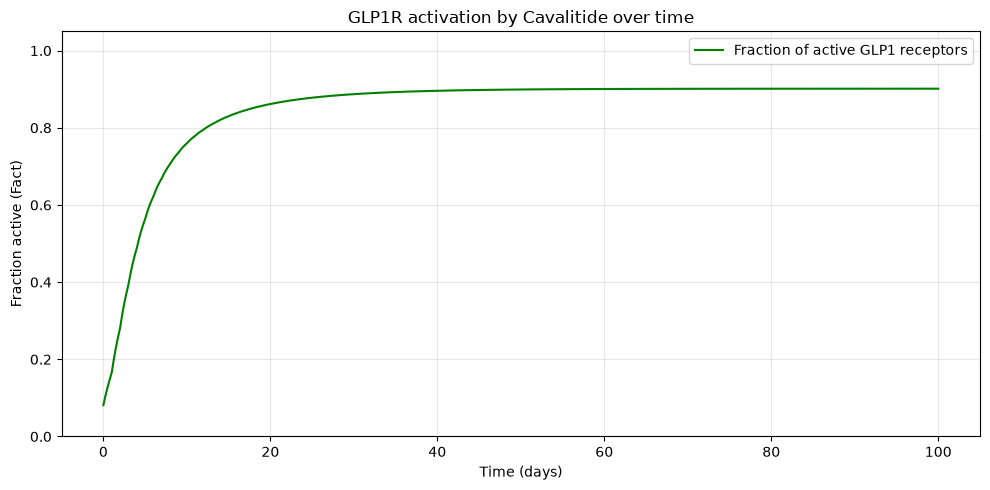

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from pathlib import Path

# ===== Cavalitide parameters =====
products = {
    'Cavalitide': dict(
        Favailable=0.01,
        ka=0.006,
        D=29,
        interval=24,
        n_doses=100,
        depot='gut (oral)'
    ),
}

# ===== Shared PK parameters =====
ke = 0.0039       # Elimination rate (1/h)
MW = 4113.6       # Molecular weight (g/mol)
Ffree = 0.01      # Free fraction of Cavalitide
V = 10.8          # Volume of distribution (L)

dt = 0.1          # Output time spacing (h)

# ===== Shared PD parameters =====
Kd1 = 0.17       # GLP1 dissociation constant (nM)
Kd2 = 0.077      # Cavalitide fitted Kd (nM)
L1 = 0.015       # Fasting GLP1 concentration (nM)

# Calculated Blood Volumes by Sex/Weight (weight derived from BMI)
volumes = [5.0, 10.8] # blood volume

# ===== Pharmacodynamic model =====
def Fact(L1, L2, Kd1, Kd2):
    """Fraction of active GLP1 receptors"""

    return (Kd2 * L1 + Kd1 * L2) / (
        Kd1 * Kd2 + Kd2 * L1 + Kd1 * L2
    )

# ===== Pharmacokinetic model =====
def ODEfunc(t, y, ka):
    Asc, Cc = y

    dAsc = -ka * Asc
    dCc = ka * Asc / V - ke * Cc

    return [dAsc, dCc]


# ===== Simulate repeated dosing using solve_ivp =====
def simulate(D, n_doses, interval, ka, Favailable, dt):

    t_out, Asc_out, Cc_out = [], [], []

    y = np.array([0.0, 0.0])

    n_steps = int(round(interval / dt))
    t_eval = np.linspace(0, interval, n_steps + 1)

    for i in range(n_doses):

        # Add dose to the gut depot
        y[0] += Favailable * D

        t0 = i * interval

        # Solve differential equations
        sol = solve_ivp(
            ODEfunc,
            (0, interval),
            y,
            args=(ka,),
            t_eval=t_eval
        )

        if not sol.success:
            raise RuntimeError(sol.message)

        t_out.append(t0 + sol.t)
        Asc_out.append(sol.y[0])
        Cc_out.append(sol.y[1])

        # Carry the final state into the next interval
        y = sol.y[:, -1].copy()

    # Combine all dosing intervals
    t = np.concatenate(t_out)
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)

    # Convert mg/L to nM
    Cc_nM = Cc_out * 1e-3 / MW * 1e9

    return t, Asc_out, Cc_nM

# ===== Run Cavalitide PK simulation =====
results = {}

# simulates data based on cavalitide drug and dosing information
for drug, p in products.items():

    t, Asc, Cc = simulate(
        p['D'],
        p['n_doses'],
        p['interval'],
        p['ka'],
        p['Favailable'],
        dt
    )

    results[drug] = (t, Asc, Cc)

# ===== Calculate receptor activation over time =====
t_cav, Asc_cav, Cc_cav = results['Cavalitide']

# Convert total blood concentration to free concentration
L2_free = Ffree * Cc_cav

# Calculate fraction of active receptors
Fact_over_time = Fact(L1, L2_free, Kd1, Kd2)


# ===== Plot PKPD results =====
plt.figure(figsize=(10, 5))

# plots a basic version of the PKPD graph
plt.plot(
    t_cav / 24,
    Fact_over_time,
    label="Fraction of active GLP1 receptors",
    color="green"
)

plt.xlabel("Time (days)")
plt.ylabel("Fraction active (Fact)")
plt.title("GLP1R activation by Cavalitide over time")

plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

### Further Investigation of Pharmacodynamics and Pharmacokinetics and the Effect of Volume (or weight)

Additional investigating was done based on the combined PD/PK simulations by altering the volumes of distribution. This was done by calculating theoretical patients by using a Medscape blood volume estimation in obesity calculator. The calculator relies on the model found in "Estimating blood volume in obese and morbidly obese patients" with the following equation: 

*BV = 70/ sqrt(BMI/22)*

Where: 

BV = Blood Volume (mL/kg)

BMI = Body Mass Index (kg/m^2)

BMI = weight (kg) / height^2 (m^2)

(Lemmens et al., 2006)

Additionally, by considering the variance of the population including those with obesity, dosing strategies can be altered to fit the needs of patients as their weights change as well as across patients that have different initial weights to meet the target Fact of 0.9 for cavalitide.​ This is important as altering the dosing of similar drugs like semaglutide can help patients using GLP1 drugs handle symptoms of the drugs to keep them on the drug longer and maintaining their quality of life.

In [ ]:
# ===== Run Cavalitide PK simulation Mutiple Volumes =====
results = []

# simulates data based on cavalitide drug and dosing information
for volume in volumes:
    V = volume      # volume of distribution (L)
    for drug, p in products.items():

        t, Asc, Cc = simulate(
            p['D'],
            p['n_doses'],
            p['interval'],
            p['ka'],
            p['Favailable'],
            dt
        )

        results.append([t, Asc, Cc])

t_cav = []
Asc_cav = []
Cc_cav = []
Fact_over_time = []

for result in results:
    # ===== Calculate receptor activation over time =====
    t_cav.append(result[0])
    Asc_cav.append(result[1])
    Cc_cav.append(result[2])

    # Convert total blood concentration to free concentration
    L2_free = Ffree * result[2] # result[2] == Cc_cav => L2_free = Ffree * Cc_cav

    # Calculate fraction of active receptors
    Fact_over_time.append(Fact(L1, L2_free, Kd1, Kd2))

index = 0
line_type = ["-", "--", ":", "-."] # goes through different line types as to distinguish between the overlapping graphs

# ===== Plot PKPD results =====
plt.figure(figsize=(10, 5))

# plots all results based on the length of the results list
while index < len(results):
    plt.plot(
        t_cav[index] / 24,
        Fact_over_time[index],
        label=f"Fraction of active GLP1 receptors (Volume = {volumes[index]:.3f})",
        color= "orange",
        linestyle = line_type[index]
        )

    index += 1

plt.xlabel("Time (days)")
plt.ylabel("Fraction active (Fact)")
plt.title("GLP1R Activation by Cavalitide Over Time (29 mg per 24 hr.)")

plt.axhline(0.9, ls=":", c="black", lw=1) # creates dashed line at the target Fact (0.9)
plt.text(0, 0.925, "Target Fact = 0.9")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.tight_layout()
plt.show()

# ===== Run Cavalitide PK Simulation Changing Dose Interval =====

# clears all lists used in the previous code chunk as to plot new data points
results.clear()
t_cav.clear()
Asc_cav.clear()
Cc_cav.clear()
Fact_over_time.clear()

# altered dosing interval and number of doses to remain within a 100 day timframe
products['Cavalitide']['interval'] = 48
products['Cavalitide']['n_doses'] = 50

# simulates data based on cavalitide drug and dosing information
for volume in volumes:
    V = volume      # volume of distribution (L)
    for drug, p in products.items():

        t, Asc, Cc = simulate(
            p['D'],
            p['n_doses'],
            p['interval'],
            p['ka'],
            p['Favailable'],
            dt
        )

        results.append([t, Asc, Cc])

for result in results:
    # ===== Calculate receptor activation over time =====
    t_cav.append(result[0])
    Asc_cav.append(result[1])
    Cc_cav.append(result[2])

    # Convert total blood concentration to free concentration
    L2_free = Ffree * result[2] # result[2] == Cc_cav => L2_free = Ffree * Cc_cav

    # Calculate fraction of active receptors
    Fact_over_time.append(Fact(L1, L2_free, Kd1, Kd2))

index = 0

# ===== Plot PKPD results =====
plt.figure(figsize=(10, 5))

while index < len(results):
    plt.plot(
        t_cav[index] / 24,
        Fact_over_time[index],
        label=f"Fraction of active GLP1 receptors (Volume = {volumes[index]:.3f})",
        color= "orange",
        linestyle = line_type[index]
        )

    index += 1

plt.xlabel("Time (days)")
plt.ylabel("Fraction active (Fact)")
plt.title("GLP1R Activation by Cavalitide Over Time (29 mg per 48 hr.)")

plt.axhline(0.9, ls=":", c="black", lw=1)
plt.text(0, 0.925, "Target Fact = 0.9")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.tight_layout()
plt.show()

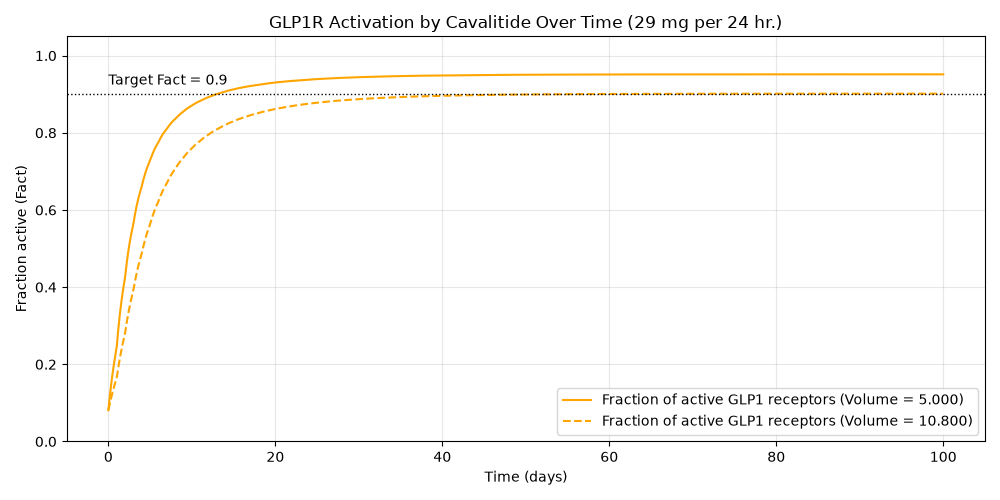

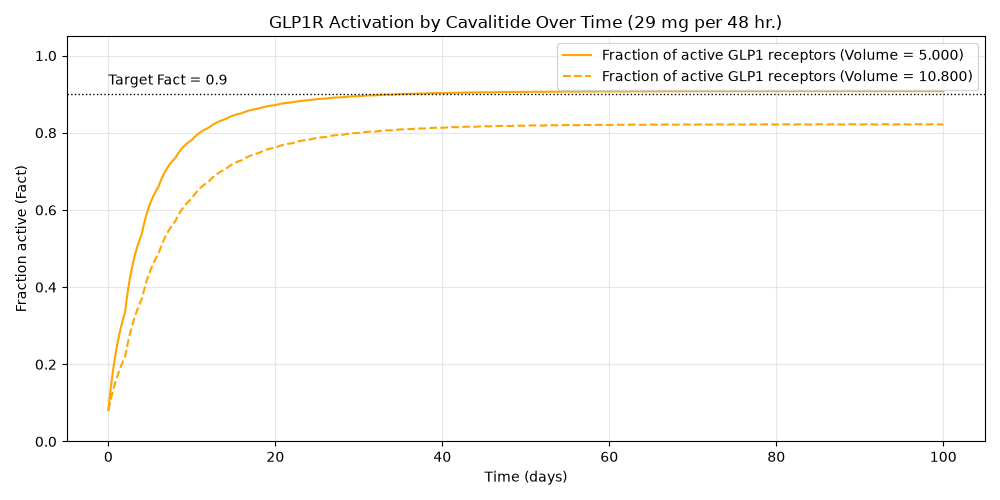

## Conclusions:

Our computational analyses suggest that Cavalitide has potential as an alternative GLP-1 receptor agonist to semaglutide. In Task 1, Cavalitide had a fitted binding affinity (Kd) of 0.077 nM, compared with approximately 0.35 nM for semaglutide. Since a lower Kd indicates stronger binding affinity, our results suggest that Cavalitide may bind more strongly to GLP-1 receptors under the conditions of our model.

In Task 2, we simulated Cavalitide as a daily oral medication and optimized its dose to 21 mg per day to achieve a free blood concentration close to our target of 0.5 nM. In Task 3, we combined the pharmacokinetic and pharmacodynamic models and increased the daily dose to 29 mg to approach approximately 90% GLP-1 receptor activation at steady state. These results demonstrate how computational modeling can help evaluate drug concentrations over time and guide dosing strategies toward a desired level of receptor activity.

Cavalitide's potential advantage is that it could provide an oral treatment option with strong predicted receptor binding and a convenient daily dosing schedule. However, our simulations do not establish that Cavalitide is more effective or safer than semaglutide in patients. Factors such as side effects, long-term safety, patient variability, absorption, and accessibility would need further investigation. Additional experimental validation and clinical trials would be necessary to determine whether Cavalitide could become a viable competitor to existing GLP-1 medications.

## Verification:

To verify our computational models, we compared our predicted semaglutide results with published literature and evaluated how closely our models fit the experimental data. For Task 1, our fitted semaglutide dissociation constant (Kd) was 0.35 nM, which was close to the published value of 0.38 ± 0.06 nM reported by Lau et al. (2015). This agreement supports the accuracy of our receptor-binding model. Our curve-fitting results also produced relatively low sums of squared errors (SSE), with 0.0044 for semaglutide and 0.0052 for Cavalitide, indicating that both models fit their respective experimental datasets reasonably well.

For Task 2, we compared the pharmacokinetic parameters used in our Ozempic and Wegovy simulations with published semaglutide information. According to the FDA prescribing information, injectable semaglutide has an absolute bioavailability of approximately 89%, while oral semaglutide has an estimated bioavailability of approximately 1–2% (U.S. Food and Drug Administration, 2026). Our model used bioavailability values of 0.89 for weekly injectable Ozempic and 0.01 for daily oral Wegovy, which are consistent with these published values. The FDA also reports an apparent volume of distribution of approximately 12.5 L and an elimination half-life of approximately one week. Our model used a volume of distribution of 10.8 L and an elimination rate of 0.0039 h⁻¹. The elimination rate corresponds to an estimated half-life of approximately 7.4 days, which is reasonably close to the published one-week half-life. Although our volume of distribution differs slightly from the published value, it provides a reasonable approximation for our simplified model.

The absorption rate constants used in our simulations were 0.029 h⁻¹ for injectable Ozempic and 0.0029 h⁻¹ for oral Wegovy. These values were model parameters rather than independently verified values from the FDA prescribing information. Similarly, the free-drug fraction used in our model was a simplifying assumption. Therefore, these parameters should be interpreted as modeling inputs rather than experimentally confirmed values.

There is currently no published clinical or pharmacokinetic literature for Cavalitide because it is a hypothetical drug developed for this project. As a result, we could not directly validate its predicted binding affinity, absorption, or dosing results against clinical measurements. Instead, we used published semaglutide data to evaluate whether our modeling approach produced reasonable results for an established GLP-1 medication. The close agreement between our predicted and published semaglutide binding affinity, along with the consistency of the pharmacokinetic parameters, supports the use of our models as a starting point for predicting Cavalitide's behavior.

Overall, our verification results suggest that our code and modeling approach performed as expected with the available experimental and literature data. However, the Cavalitide predictions remain theoretical and would require additional experimental testing and clinical data for further validation.

## Limitations and Future Work:

Describe the limitations of your project. If you had more time or additional data, explain how you would improve the analysis.



## AI Usage Statement:
We used ChatGPT (OpenAI) to assist with Python code troubleshooting, implementing the solve_ivp function for pharmacokinetic simulations, and understanding and interpreting our model results. We also used it to improve the clarity, grammar, and organization of our written explanations. We reviewed and modified AI-generated suggestions and used our own code, simulations, and analysis to guide our final results and conclusions.​

## GitHub Repository Link:
*Please provide the link to your shared GitHub repository that includes this notebook and any other scripts, notebooks, or data that you used for this project.*


## References:

Centers for Disease Control and Prevention. (2024, September). *Obesity and severe obesity prevalence in adults: United States, August 2021–August 2023*. https://www.cdc.gov/nchs/products/databriefs/db508.htm

Drucker, D. J. (2022). GLP-1 physiology informs the pharmacotherapy of obesity. *Molecular Metabolism, 57*, 101351. https://doi.org/10.1016/j.molmet.2021.101351

Fornes, A., Huff, J., Pritchard, R. I., & Godfrey, M. (2022). Once-weekly semaglutide for weight management: A clinical review. *Journal of Pharmacy Technology, 38*(4). https://doi.org/10.1177/87551225221092681

Khalid, A. S., & Arsalan, M. R. (2025). Obesity: Prevalence, causes, consequences, management, preventive strategies and future research directions. *Metabolism Open, 27*, 100375. https://doi.org/10.1016/j.metop.2025.100375

Lau, J., Bloch, P., Schäffer, L., Pettersson, I., Spetzler, J., Kofoed, J., et al. (2015). Discovery of the once-weekly glucagon-like peptide-1 (GLP-1) analogue semaglutide. *Journal of Medicinal Chemistry, 58*(18), 7370–7380. https://doi.org/10.1021/acs.jmedchem.5b00726

Lemmens, H. J. M., Bernstein, D. P., & Brodsky, J. B. (2006). Estimating blood volume in obese and morbidly obese patients. *Obesity Surgery, 16*(6), 773–776. https://doi.org/10.1381/096089206777346673

Moiz, A., Filion, K. B., Tsoukas, M. A., Yu, O. H. Y., Peters, T. M., & Eisenberg, M. J. (2025). Mechanisms of GLP-1 receptor agonist-induced weight loss: A review of central and peripheral pathways in appetite and energy regulation. *The American Journal of Medicine, 138*(6). https://doi.org/10.1016/j.amjmed.2025.01.021

U.S. Food and Drug Administration. (2024). *FDA alerts health care providers, compounders, and patients of dosing errors associated with compounded injectable semaglutide products*. https://www.fda.gov/drugs/human-drug-compounding/fda-alerts-health-care-providers-compounders-and-patients-dosing-errors-associated-compounded

U.S. Food and Drug Administration. (2025). *Ozempic (semaglutide) prescribing information*. https://www.accessdata.fda.gov/drugsatfda_docs/label/2025/209637s025lbl.pdf

U.S. Food and Drug Administration. (2026). *Wegovy (semaglutide) prescribing information*. https://www.accessdata.fda.gov/drugsatfda_docs/label/2026/218316s002lbl.pdf